# 04 Cost-based threshold analysis (training set only)

The single extension: how sensitivity, specificity and expected cost change with the classification threshold for the model selected in notebook 03, how much screening with the model saves over policies that use no model, and how sensitive these conclusions are to the assumed cost ratio. Everything uses the grouped out-of-fold CV probabilities from the training set. The test set is not loaded.

## Decisions fixed before looking at any results

- **Costs** (from notebook 03): $c_{FP} = 1$ (one wasted tasting), $c_{FN} = r$ (lost premium margin), base case $r = 3$. Expected cost per wine $= (FP + r \cdot FN)/n$.
- **Cost ratios for the sensitivity check:** $r \in \{1/3, 1/2, 1, 2, 3, 5, 10\}$. Ratios below 1 cover the other framing (for example, choosing wines for a premium shelf), where a false positive costs more.
- **Operating point rule:** the threshold on a 0.01 grid that minimises the pooled out-of-fold expected cost at $r = 3$. The theoretical $t^* = 1/(1+r)$ is reported alongside it.
- **No-model policies**, with $\pi$ the share of good wines: *taste none* costs $r\pi$ per wine and *taste all* costs $c_{FP}(1-\pi) = 1-\pi$. The model's **saving** is measured against the cheaper of the two, in absolute terms (cost units per wine) and as a % of that cost.
- **Break-even range:** with the threshold frozen at the operating point, the model beats *taste all* when $FP + r\,FN < FP + TN$, i.e. $r < TN/FN$, and beats *taste none* when $FP + r\,FN < r(TP + FN)$, i.e. $r > FP/TP$. So it beats both for $FP/TP < r < TN/FN$.
- **Uncertainty of the operating point:** a bootstrap over wines (resampling `wine_id`s, so copies of a wine stay together), 2,000 replicates, re-finding the optimal threshold at $r = 3$ each time.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

from wine_utils import expected_cost, no_model_costs, COST_RATIOS, C_FN_BASE, C_FP, SEED

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

def ratio_label(r):
    return f'1/{1 / r:g}' if r < 1 else f'{r:g}'

spec = json.load(open('results/selected_model.json'))
oof = pd.read_csv('results/oof_probabilities.csv', index_col=0)
y, prob, fold = oof['y'].values, oof[spec['name']].values, oof['fold'].values
wine_id = oof['wine_id'].values
pi = y.mean()
n = len(y)
grid = np.round(np.arange(0.01, 1.00, 0.01), 2)

# FP and FN counts at every grid threshold, so cost(t, r) = (FP + r FN) / n
flag = prob[:, None] >= grid[None, :]
FP_t = (flag & (y[:, None] == 0)).sum(0)
FN_t = (~flag & (y[:, None] == 1)).sum(0)
print('Selected model:', spec['name'], '| rows =', n, '| share good =', round(pi, 3))

Selected model: Logistic | rows = 3926 | share good = 0.216


## Sensitivity and specificity against the threshold

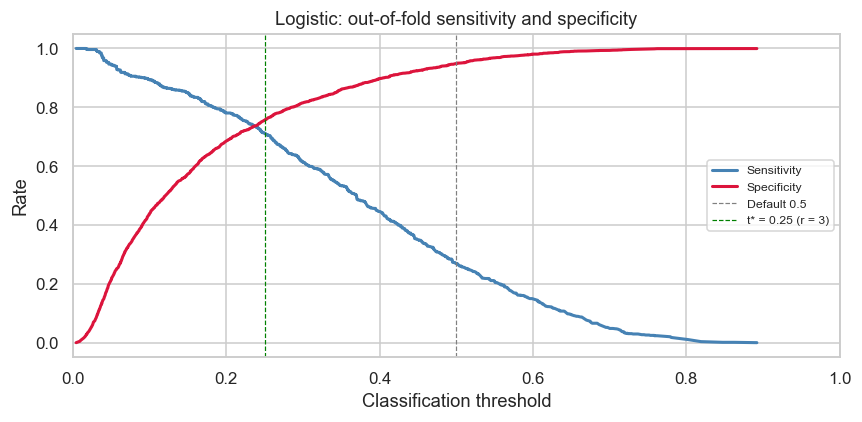

In [2]:
fpr, tpr, thr = roc_curve(y, prob)
fpr, tpr, thr = fpr[1:], tpr[1:], thr[1:]   # drop the artificial infinite threshold

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr, tpr, lw=2, color='steelblue', label='Sensitivity')
ax.plot(thr, 1 - fpr, lw=2, color='crimson', label='Specificity')
ax.axvline(0.5, color='grey', ls='--', lw=0.8, label='Default 0.5')
ax.axvline(1 / (1 + C_FN_BASE), color='green', ls='--', lw=0.8,
           label=f't* = {1 / (1 + C_FN_BASE):.2f} (r = {C_FN_BASE})')
ax.set(xlim=(0, 1), xlabel='Classification threshold', ylabel='Rate',
       title=f'{spec["name"]}: out-of-fold sensitivity and specificity')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Expected cost against the threshold, for each cost ratio

Costs are divided by the cheaper of the two no-model policies, so a value below 1 means that screening with the model is cheaper than the best policy available without one.

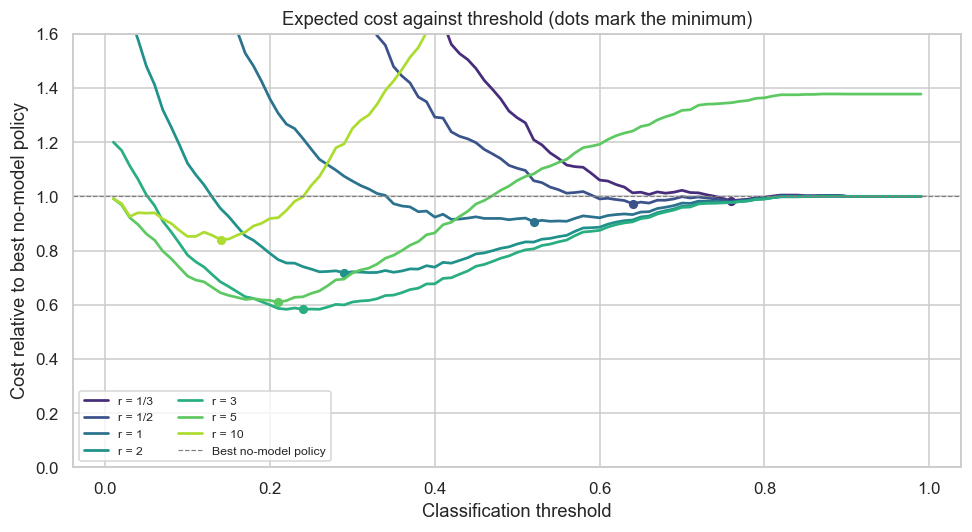

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = sns.color_palette('viridis', len(COST_RATIOS))
for r, col in zip(COST_RATIOS, colors):
    trivial = min(no_model_costs(pi, r).values())
    cost = (FP_t + r * FN_t) / n / trivial
    ax.plot(grid, cost, color=col, lw=1.8, label=f'r = {ratio_label(r)}')
    ax.plot(grid[cost.argmin()], cost.min(), 'o', color=col, ms=5)
ax.axhline(1, color='grey', ls='--', lw=0.8, label='Best no-model policy')
ax.set(xlabel='Classification threshold', ylabel='Cost relative to best no-model policy',
       title='Expected cost against threshold (dots mark the minimum)', ylim=(0, 1.6))
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## Sensitivity check across cost ratios

For each ratio: the theoretical $t^*$, the empirically optimal threshold on the pooled out-of-fold probabilities, the spread of the optimal threshold when it is found separately in each of the 10 folds, the range of thresholds whose cost stays within 5% of the minimum (how flat the cost curve is), and the saving over the better no-model policy.

In [4]:
def best_threshold(y_, p_, r):
    costs = np.array([expected_cost(y_, p_, t, r) for t in grid])
    return grid[costs.argmin()], costs

rows = []
for r in COST_RATIOS:
    costs = (FP_t + r * FN_t) / n
    t_opt = grid[costs.argmin()]
    per_fold = [best_threshold(y[fold == k], prob[fold == k], r)[0] for k in np.unique(fold)]
    flat = grid[costs <= 1.05 * costs.min()]
    nm = no_model_costs(pi, r)
    best_nm = min(nm, key=nm.get)
    rows.append({
        'r = c_FN/c_FP': r,
        't* theory': 1 / (1 + r),
        't optimal (pooled)': t_opt,
        'fold optimum mean': np.mean(per_fold),
        'fold optimum SD': np.std(per_fold, ddof=1),
        'within 5% of min': f'{flat.min():.2f}-{flat.max():.2f}',
        'cost @ t optimal': costs.min(),
        'cost @ t*': expected_cost(y, prob, 1 / (1 + r), r),
        'cost @ 0.5': expected_cost(y, prob, 0.5, r),
        'taste none': nm['taste none'],
        'taste all': nm['taste all'],
        'better no-model': best_nm,
        'saving (abs)': nm[best_nm] - costs.min(),
        'saving (%)': 100 * (1 - costs.min() / nm[best_nm]),
    })
sens = pd.DataFrame(rows)
sens.round(3)

,r = c_FN/c_FP,t* theory,t optimal (pooled),fold optimum mean,fold optimum SD,within 5% of min,cost @ t optimal,cost @ t*,cost @ 0.5,taste none,taste all,better no-model,saving (abs),saving (%)
0,0.333,0.750,0.76,0.704,0.097,0.64-0.99,0.071,0.071,0.093,0.072,0.784,taste none,0.001,1.651
1,0.500,0.667,0.64,0.620,0.083,0.56-0.99,0.105,0.106,0.119,0.108,0.784,taste none,0.003,2.712
2,1.000,0.500,0.52,0.467,0.071,0.38-0.66,0.196,0.198,0.198,0.216,0.784,taste none,0.020,9.316
3,2.000,0.333,0.29,0.300,0.057,0.23-0.42,0.310,0.311,0.356,0.432,0.784,taste none,0.122,28.184
4,3.000,0.250,0.24,0.258,0.044,0.19-0.30,0.378,0.379,0.514,0.648,0.784,taste none,0.270,41.706
5,5.000,0.167,0.21,0.198,0.039,0.15-0.24,0.478,0.488,0.830,1.080,0.784,taste all,0.306,39.051
6,10.000,0.091,0.14,0.116,0.063,0.09-0.17,0.659,0.682,1.619,2.160,0.784,taste all,0.125,15.919


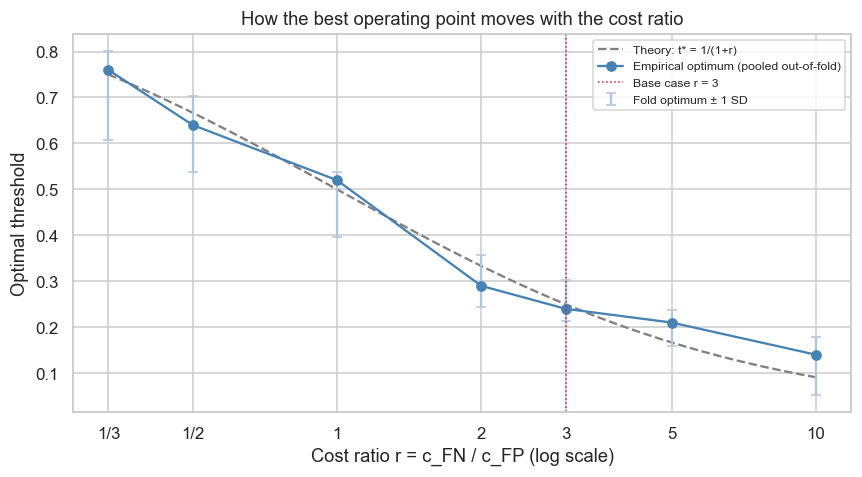

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
r_fine = np.logspace(np.log10(1/3), 1, 100)
ax.plot(r_fine, 1 / (1 + r_fine), color='grey', ls='--', label='Theory: t* = 1/(1+r)')
ax.errorbar(sens['r = c_FN/c_FP'], sens['fold optimum mean'], yerr=sens['fold optimum SD'],
            fmt='none', ecolor='lightsteelblue', capsize=3, label='Fold optimum ± 1 SD')
ax.plot(sens['r = c_FN/c_FP'], sens['t optimal (pooled)'], 'o-', color='steelblue',
        label='Empirical optimum (pooled out-of-fold)')
ax.axvline(C_FN_BASE, color='crimson', ls=':', lw=1, label=f'Base case r = {C_FN_BASE}')
ax.set_xscale('log')
ax.set_xticks(COST_RATIOS, [ratio_label(r) for r in COST_RATIOS])
ax.set(xlabel='Cost ratio r = c_FN / c_FP (log scale)', ylabel='Optimal threshold',
       title='How the best operating point moves with the cost ratio')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Calibration.** At the base case the empirical optimum (0.24) is close to the theoretical $t^* = 0.25$, but it sits above $t^*$ at high cost ratios (0.21 vs 0.17 at $r = 5$, 0.14 vs 0.09 at $r = 10$), so the predicted probabilities are not perfectly calibrated in the low range; we note this but do not analyse calibration further.

## Operating point (base case $r = 3$)

In [6]:
base = sens.loc[sens['r = c_FN/c_FP'] == C_FN_BASE].iloc[0]
t_op = float(base['t optimal (pooled)'])
pred = prob >= t_op
tp, fp = int(np.sum(pred & (y == 1))), int(np.sum(pred & (y == 0)))
fn, tn = int(np.sum(~pred & (y == 1))), int(np.sum(~pred & (y == 0)))
precision = tp / (tp + fp)

per_1000 = pd.Series({
    'Sent to the panel': 1000 * (tp + fp) / n,
    '  of which good (caught)': 1000 * tp / n,
    '  of which not good (wasted tastings)': 1000 * fp / n,
    'Good wines not sent (missed)': 1000 * fn / n,
    'Good wines in total': 1000 * pi,
    'Precision of panel referrals (%)': 100 * precision,
    'Base rate of good wines (%)': 100 * pi,
}, name=f'Per 1,000 wines at threshold {t_op:g} (r = {C_FN_BASE})')
print(f'Sensitivity {tp / (tp + fn):.3f}, specificity {tn / (tn + fp):.3f}, '
      f'cost per wine {base["cost @ t optimal"]:.3f}')
per_1000.round(1).to_frame()

Sensitivity 0.732, specificity 0.739, cost per wine 0.378


,"Per 1,000 wines at threshold 0.24 (r = 3)"
Sent to the panel,362.5
of which good (caught),158.2
of which not good (wasted tastings),204.3
Good wines not sent (missed),57.8
Good wines in total,216.0
Precision of panel referrals (%),43.6
Base rate of good wines (%),21.6


**Takeaway.** Per 1,000 wines, screening at threshold 0.24 sends about 363 to the panel and catches 158 of the 216 good wines (73%), missing 58; 44% of the wines sent to the panel are good, about twice the 21.6% base rate.

## Saving over the no-model policies

Solid line: the model with its threshold re-optimised for each cost ratio. Dashed line: the model with its threshold frozen at the base-case operating point, which is what the producer would use if the true ratio differs from 3. The shaded band is the break-even range of the frozen threshold.

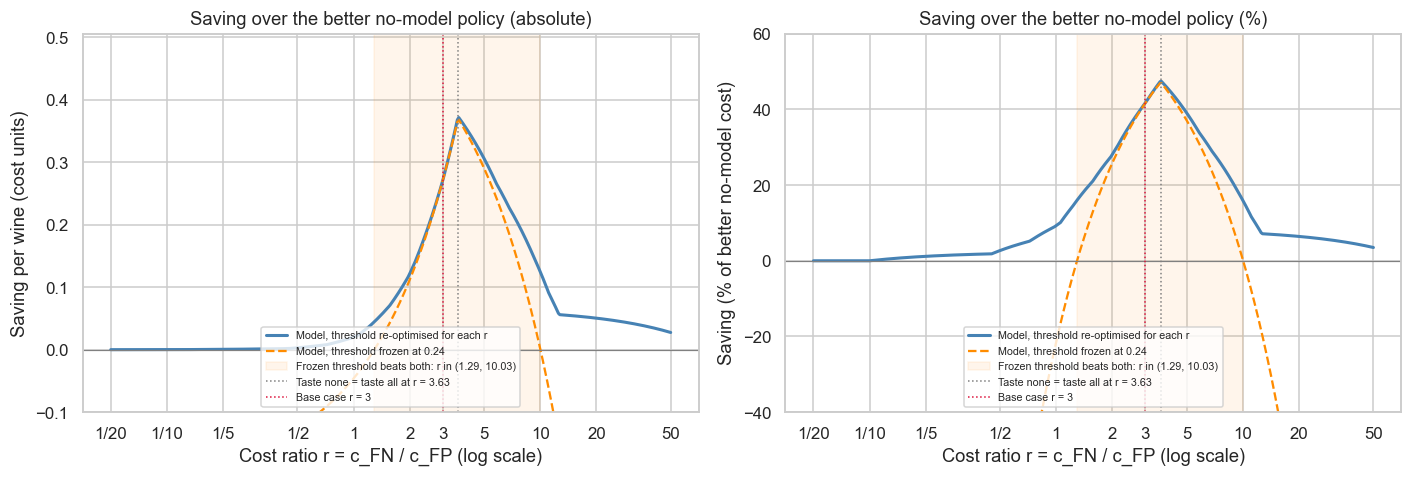

Break-even range of the frozen threshold: 1.29 < r < 10.03
Largest absolute saving (re-optimised): 0.372 per wine at r = 3.66
At r = 3: saving 0.270 per wine, 41.7% of the better no-model policy (taste none)


In [7]:
r_grid = np.logspace(np.log10(1/20), np.log10(50), 400)
best_nm = np.minimum(r_grid * pi, 1 - pi)
reopt = np.array([((FP_t + r * FN_t) / n).min() for r in r_grid])
frozen = (fp + r_grid * fn) / n

lo_be, hi_be = fp / tp, tn / fn
beats = (frozen < r_grid * pi) & (frozen < 1 - pi)
assert np.isclose(r_grid[beats].min(), lo_be, rtol=0.02) and np.isclose(r_grid[beats].max(), hi_be, rtol=0.02)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, scale, ylab in [(axes[0], 1, 'Saving per wine (cost units)'),
                        (axes[1], 100, 'Saving (% of better no-model cost)')]:
    denom = best_nm if scale == 100 else 1
    ax.plot(r_grid, scale * (best_nm - reopt) / denom, lw=2, color='steelblue',
            label='Model, threshold re-optimised for each r')
    ax.plot(r_grid, scale * (best_nm - frozen) / denom, lw=1.5, ls='--', color='darkorange',
            label=f'Model, threshold frozen at {t_op:g}')
    ax.axvspan(lo_be, hi_be, color='darkorange', alpha=0.08,
               label=f'Frozen threshold beats both: r in ({lo_be:.2f}, {hi_be:.2f})')
    ax.axhline(0, color='grey', lw=0.8)
    ax.axvline((1 - pi) / pi, color='grey', ls=':', lw=1,
               label=f'Taste none = taste all at r = {(1 - pi) / pi:.2f}')
    ax.axvline(C_FN_BASE, color='crimson', ls=':', lw=1, label=f'Base case r = {C_FN_BASE}')
    ax.set_xscale('log')
    ticks = [0.05, 0.1, 0.2, 0.5, 1, 2, 3, 5, 10, 20, 50]
    ax.set_xticks(ticks, [ratio_label(r) for r in ticks])
    ax.set(xlabel='Cost ratio r = c_FN / c_FP (log scale)', ylabel=ylab)
    ax.legend(fontsize=7, loc='lower center')
axes[0].set_ylim(bottom=-0.1)
axes[1].set_ylim(-40, 60)
axes[0].set_title('Saving over the better no-model policy (absolute)')
axes[1].set_title('Saving over the better no-model policy (%)')
plt.tight_layout()
plt.show()

i_peak = np.argmax(best_nm - reopt)
print(f'Break-even range of the frozen threshold: {lo_be:.2f} < r < {hi_be:.2f}')
print(f'Largest absolute saving (re-optimised): {(best_nm - reopt)[i_peak]:.3f} per wine at r = {r_grid[i_peak]:.2f}')
print(f'At r = {C_FN_BASE}: saving {base["saving (abs)"]:.3f} per wine, '
      f'{base["saving (%)"]:.1f}% of the better no-model policy ({base["better no-model"]})')

**Where the model is worth using.** With its threshold re-optimised for each ratio, the model never costs more than the better no-model policy, but the saving is only material in the middle range: under 3% for $r \le 1/2$, 9% at $r = 1$, 28-42% for $r$ from 2 to 5, and 16% at $r = 10$. The largest absolute saving, 0.372 per wine, is at $r \approx 3.66$, next to the point ($r = 3.63$) where *taste none* and *taste all* cost the same. The saving shrinks at both extremes because one no-model policy is then already almost optimal. When misses are cheap (small $r$), tasting nothing is nearly the best possible, and the model can only help by flagging the few wines it is very confident are good. When misses are expensive (large $r$), tasting nearly everything is nearly the best possible, and the model can only help by ruling out the few wines it is very confident are not good. In between, the model's ranking changes the decision for many wines.

**Break-even and the choice of $c_{FN} = 3$.** With the threshold frozen at 0.24, the model beats both no-model policies for $1.29 < r < 10.03$, and the base case $r = 3$ sits well inside this range. So the decision to screen with the model does not hinge on $c_{FN}$ being exactly 3: any ratio between about 1.3 and 10 leads to the same conclusion. Below about 1.3 tasting nothing is cheaper, and above about 10 tasting everything is cheaper, unless the threshold is re-tuned. **TODO (group):** once the justification for $c_{FN}$ is written in notebook 03, state whether its plausible range lies inside (1.29, 10.03).

## Bootstrap interval for the optimal threshold at $r = 3$

Optimal threshold at r = 3: 0.24; 95% bootstrap interval 0.21-0.29 (theory t* = 0.25)


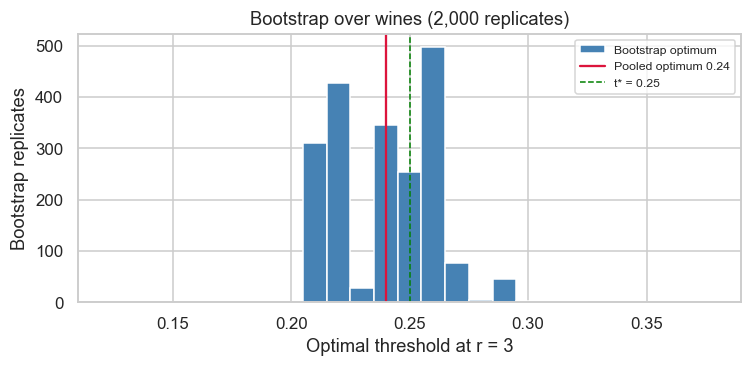

In [8]:
rng = np.random.default_rng(SEED)
ids, row_group = np.unique(wine_id, return_inverse=True)
cost_cols = np.where(y[:, None] == 1, C_FN_BASE * ~flag, C_FP * flag).astype(float)  # rows x grid
B = 2000
t_boot = np.empty(B)
for b in range(B):
    w = np.bincount(rng.integers(0, len(ids), len(ids)), minlength=len(ids))[row_group]
    t_boot[b] = grid[(w @ cost_cols).argmin()]
lo_t, hi_t = np.percentile(t_boot, [2.5, 97.5])
print(f'Optimal threshold at r = {C_FN_BASE}: {t_op:g}; 95% bootstrap interval {lo_t:.2f}-{hi_t:.2f} '
      f'(theory t* = {1 / (1 + C_FN_BASE):.2f})')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(t_boot, bins=np.arange(grid.min() - 0.005, grid.max(), 0.01), color='steelblue', edgecolor='white',
        label='Bootstrap optimum')
ax.axvline(t_op, color='crimson', lw=1.5, label=f'Pooled optimum {t_op:g}')
ax.axvline(1 / (1 + C_FN_BASE), color='green', ls='--', lw=1, label=f't* = {1 / (1 + C_FN_BASE):.2f}')
ax.set(xlim=(max(0, lo_t - 0.1), hi_t + 0.1), xlabel='Optimal threshold at r = 3',
       ylabel='Bootstrap replicates', title='Bootstrap over wines (2,000 replicates)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Resampling wines gives a 95% interval of 0.21-0.29 for the optimal threshold at $r = 3$. It contains the theoretical $t^* = 0.25$, and the cost curve stays within 5% of its minimum for thresholds 0.19-0.30, so the exact threshold within this band matters little.

## Save the operating point

In [9]:
nm = no_model_costs(pi, C_FN_BASE)
operating_point = {
    'model': spec['name'], 'cost_ratio': C_FN_BASE, 'threshold': t_op,
    'theoretical_threshold': 1 / (1 + C_FN_BASE),
    'threshold_bootstrap_95ci': [float(lo_t), float(hi_t)],
    'cv_share_good': float(pi),
    'cv_sensitivity': tp / (tp + fn), 'cv_specificity': tn / (tn + fp),
    'cv_precision': precision,
    'cv_cost_per_wine': float(base['cost @ t optimal']),
    'cv_cost_taste_none': float(nm['taste none']), 'cv_cost_taste_all': float(nm['taste all']),
    'cv_saving_abs': float(base['saving (abs)']), 'cv_saving_pct': float(base['saving (%)']),
    'break_even_cost_ratio': [float(lo_be), float(hi_be)],
}
with open('results/operating_point.json', 'w') as f:
    json.dump(operating_point, f, indent=2)
operating_point

{'model': 'Logistic',
 'cost_ratio': 3,
 'threshold': 0.24,
 'theoretical_threshold': 0.25,
 'threshold_bootstrap_95ci': [0.21, 0.29],
 'cv_share_good': 0.21599592460519612,
 'cv_sensitivity': 0.7323113207547169,
 'cv_specificity': 0.7394411955815464,
 'cv_precision': 0.4364019676739283,
 'cv_cost_per_wine': 0.37773815588385123,
 'cv_cost_taste_none': 0.6479877738155884,
 'cv_cost_taste_all': 0.7840040753948039,
 'cv_saving_abs': 0.27024961793173713,
 'cv_saving_pct': 41.70597484276729,
 'break_even_cost_ratio': [1.2914653784219001, 10.026431718061675]}